# 1. From AnnData to cell graphs

This vignette turns a public spatial-proteomics dataset into the inputs GRASS-MIL
reads, builds the cell graphs, and defines the phenotype that vignettes 2 and 3
predict and explain.

**Dataset.** `squidpy.datasets.mibitof()`: MIBI-TOF images of colorectal
carcinoma, 3 images, about 3,300 cells with 8 annotated cell types (Hartmann et
al.). `squidpy` is only used to download it.

In [1]:
# pip install 'grass-mil[io]' squidpy
import collections
import json
import pathlib

import numpy as np
import pandas as pd
import squidpy as sq

WORK = pathlib.Path("vignette_work").resolve()
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)

adata = sq.datasets.mibitof(path=WORK / "mibitof.h5ad")
print(adata.n_obs, "cells,", adata.obs["library_id"].nunique(), "images")
adata.obs["Cluster"].value_counts()

3309 cells, 3 images


Cluster
Tcell_CD4        799
Epithelial       746
Imm_other        488
Tcell_CD8        464
Fibroblast       270
Myeloid_CD68     259
Myeloid_CD11c    168
Endothelial      115
Name: count, dtype: int64

## Cell tables and manifest

GRASS-MIL reads one cell table per region, listed in a manifest. Here every image
is one region, saved as an h5ad file with the cell type in `obs["cell_type"]` and
the coordinates in `obsm["spatial"]`. Only the cell type enters the model
(`data.input.features=null`), so any assay with harmonised cell types can be
analysed the same way.

In [2]:
rows = []
for image in sorted(adata.obs["library_id"].unique()):
    sub = adata[adata.obs["library_id"] == image].copy()
    sub.obs = pd.DataFrame({"cell_type": sub.obs["Cluster"].astype(str)}, index=sub.obs_names)
    sub.write_h5ad(DATA / f"{image}.h5ad")
    rows.append({"sample_id": image, "input_path": f"{image}.h5ad"})
pd.DataFrame(rows).to_csv(DATA / "manifest.csv", index=False)
pd.DataFrame(rows)

,sample_id,input_path
0,point16,point16.h5ad
1,point23,point23.h5ad
2,point8,point8.h5ad


## Settings shared by every command

Each image is about 1,024 pixels wide at 0.39 µm per pixel, so
`coord_scale_um=0.39` puts every distance in micrometres. The images are cut into
100 µm tiles (`data.unit=tile`); a tile is one bag, one label and one
cross-validation member. Cells within 20 µm of each other are flagged as
neighbours on the graph edges.

The same overrides are passed to every command in vignettes 2 and 3, so they are
stored once in `cohort.json` (in your own project they belong in a cohort file,
`configs/experiment/example_cohort.yaml`).

In [3]:
overrides = [
    f"data.manifest_path={DATA / 'manifest.csv'}",
    f"data.processed_dir={DATA / 'processed'}",
    "data.unit=tile",
    "data.tiling.size=100",
    "data.tiling.stride=100",
    "data.coord_scale_um=0.39",
    "data.min_cells=20",
    "data.input.features=null",
    "data.graph.neighbor_cutoff=20",
    f"data.labels.file={DATA / 'labels.csv'}",
    "data.labels.id_column=unit_id",
    "data.labels.patient_column=image",
    "task.target_columns=[infiltrated]",
    f"paths.log_dir={WORK / 'logs'}",
]
(WORK / "cohort.json").write_text(json.dumps({"overrides": overrides}, indent=1))
print(len(overrides), "settings saved to cohort.json")

14 settings saved to cohort.json


## Build the graphs

Every command builds the graphs on first use; here we build them directly with
the datamodule the commands use. Every tile becomes a Delaunay graph of its
cells, with the bounded log edge length (`log_distance`) and the `neighbor`
flag as edge features.

In [4]:
from hydra import compose, initialize_config_module
from hydra.utils import instantiate

with initialize_config_module(version_base="1.3", config_module="grass_mil.configs"):
    cfg = compose(
        "train", overrides=[o for o in overrides if not o.startswith("data.labels.file")]
    )
datamodule = instantiate(cfg.data, _recursive_=False)
datamodule.prepare_data()
units = datamodule.all_units()
print(len(units), "tiles; cell types:", datamodule.input_spec.cell_types)
print("tiles per image:", dict(collections.Counter(e.region_id for e in units.entries)))

44 tiles; cell types: ('Endothelial', 'Epithelial', 'Fibroblast', 'Imm_other', 'Myeloid_CD11c', 'Myeloid_CD68', 'Tcell_CD4', 'Tcell_CD8')
tiles per image: {'point16': 16, 'point23': 12, 'point8': 16}


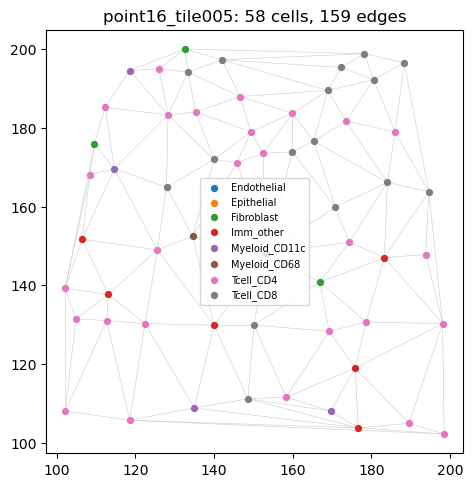

In [5]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

g = units[5]
pos, types = g.pos.numpy(), g.cell_type.numpy()
src, dst = g.edge_index.numpy()
keep = src < dst
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_collection(
    LineCollection(np.stack([pos[src[keep]], pos[dst[keep]]], 1), lw=0.4, colors="0.8")
)
for code, name in enumerate(datamodule.input_spec.cell_types):
    m = types == code
    ax.scatter(pos[m, 0], pos[m, 1], s=18, label=name, zorder=2)
ax.set_aspect("equal")
ax.set_title(f"{g.unit_id}: {g.num_nodes} cells, {keep.sum()} edges")
ax.legend(fontsize=7)
plt.show()

## A tile-level phenotype

The dataset has no clinical outcome with enough samples to learn from, so the
vignettes predict a phenotype of each tile: **CD8 T-cell infiltration**, a tile
being positive when its fraction of `Tcell_CD8` cells is at or above the median
over tiles. It is derived from the data, which makes it easy to check what the
model and the niche analysis find. Tiles are grouped by image
(`patient_column=image`) so that splits and folds never separate the tiles of
one image.

Labels are a CSV keyed by unit id; they are not part of the graphs, so they can
be changed without rebuilding them.

In [6]:
cd8 = datamodule.input_spec.cell_types.index("Tcell_CD8")
rows = []
for i, entry in enumerate(units.entries):
    fraction = float((units[i].cell_type == cd8).float().mean())
    rows.append({"unit_id": entry.unit_id, "image": entry.region_id, "cd8_fraction": fraction})
labels = pd.DataFrame(rows)
labels["infiltrated"] = (labels["cd8_fraction"] >= labels["cd8_fraction"].median()).astype(int)
labels.to_csv(DATA / "labels.csv", index=False)
labels.groupby("image")["infiltrated"].agg(["count", "sum"])

,count,sum
image,,
point16,16,10
point23,12,7
point8,16,5


## Folds

Cross-validation folds are a JSON list of lists of ids. Region ids select every
tile of the region, so one image per fold keeps the tiles of an image together.

In [7]:
images = sorted(labels["image"].unique())
(DATA / "folds.json").write_text(json.dumps([[image] for image in images]))
print("folds:", [[image] for image in images])

folds: [['point16'], ['point23'], ['point8']]
